In [1]:
import os
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, f1_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline

def load_pos_data(file_path):
    """
    Loads POS tagged data from a file where each line is 'word\tpos' 
    and sentences are separated by blank lines.
    """
    sentences = []
    current_sentence = []
    
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
                continue
            
            parts = line.split()
            if len(parts) >= 2:
                word = parts[0]
                tag = parts[-1]
                current_sentence.append((word, tag))
        if current_sentence:
            sentences.append(current_sentence)
            
    return sentences

# Define paths
train_path = "Hindi-POS-Data/hindi-train-pos.txt"
dev_path = "Hindi-POS-Data/hindi-dev-pos.txt"
test_path = "Hindi-POS-Data/hindi-test-pos.txt"

train_sents = load_pos_data(train_path)
dev_sents = load_pos_data(dev_path)
test_sents = load_pos_data(test_path)

print(f"Loaded {len(train_sents)} training sentences.")
print(f"Loaded {len(dev_sents)} dev sentences.")
print(f"Loaded {len(test_sents)} test sentences.")

Loaded 15087 training sentences.
Loaded 1866 dev sentences.
Loaded 1910 test sentences.


In [6]:
print("First training sentence:", train_sents[0])

First training sentence: [('यह', 'DM_DMD'), ('एशिया', 'N_NNP'), ('की', 'PSP'), ('सबसे', 'RP_INTF'), ('बड़ी', 'JJ'), ('मस्जिदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ('है', 'V_VM'), ('।', 'RD_PUNC')]


In [2]:
def extract_features(sentence, idx):
    word, tag = sentence[idx]
    
    # Feature a: Length of word
    length_feat = "MORE" if len(word) > 4 else "LESS"
    
    # Feature b: Actual Word
    curr_word = word
    
    # Feature c: Previous Word
    prev_word = sentence[idx - 1][0] if idx > 0 else "<START>"
    
    # Feature d: Next Word
    next_word = sentence[idx + 1][0] if idx < len(sentence) - 1 else "<END>"
    
    # Feature e: Previous Tag
    prev_tag = sentence[idx - 1][1] if idx > 0 else "<START>"
    
    features = {
        'length': length_feat,
        'word': curr_word,
        'prev_word': prev_word,
        'next_word': next_word,
        'prev_tag': prev_tag
    }
    return features

def prepare_dataset(sentences):
    X, y = [], []
    for sent in sentences:
        for idx in range(len(sent)):
            X.append(extract_features(sent, idx))
            y.append(sent[idx][1])
    return X, y

X_train, y_train = prepare_dataset(train_sents)
X_dev, y_dev = prepare_dataset(dev_sents)
X_test, y_test = prepare_dataset(test_sents)

# Train Naive Bayes Model using ComplementNB for robust text classification
nb_model = Pipeline([
    ('vectorizer', DictVectorizer(sparse=True)),
    ('classifier', ComplementNB())
])

nb_model.fit(X_train, y_train)

# Predictions
y_dev_pred_nb = nb_model.predict(X_dev)
y_test_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Evaluation on Dev Set:")
print(classification_report(y_dev, y_dev_pred_nb, zero_division=0))

Naive Bayes Evaluation on Dev Set:
              precision    recall  f1-score   support

      CC_CCD       0.96      0.97      0.96       829
      CC_CCS       0.96      0.96      0.96       752
      DM_DMD       0.86      0.87      0.86       499
          JJ       0.92      0.85      0.88      2370
        N_NN       0.89      0.94      0.92      9098
       N_NNP       0.91      0.82      0.86      4853
       N_NST       0.98      0.98      0.98       621
      PR_PRF       0.99      1.00      0.99       152
      PR_PRL       0.89      0.83      0.86       106
      PR_PRP       0.96      0.92      0.94      1428
      PR_PRQ       1.00      0.96      0.98        25
         PSP       0.96      0.99      0.97      8023
      QT_QTC       0.94      0.95      0.94       856
      QT_QTF       0.92      0.88      0.90       330
      QT_QTO       0.97      0.85      0.90        66
          RB       0.87      0.76      0.81       161
     RD_PUNC       0.98      1.00      0.99   

In [7]:
print("First training sentence:", X_train[0])

First training sentence: {'length': 'LESS', 'word': 'यह', 'prev_word': '<START>', 'next_word': 'एशिया', 'prev_tag': '<START>'}


In [3]:
class HMM_POS_Tagger:
    def __init__(self, smoothing=1e-5):
        self.smoothing = smoothing
        self.tags = set()
        self.vocab = set()
        self.transition_counts = defaultdict(lambda: defaultdict(int))
        self.emission_counts = defaultdict(lambda: defaultdict(int))
        self.tag_counts = defaultdict(int)
        self.init_counts = defaultdict(int)
        
    def fit(self, sentences):
        for sent in sentences:
            self.init_counts[sent[0][1]] += 1
            for idx, (word, tag) in enumerate(sent):
                self.tags.add(tag)
                self.vocab.add(word)
                self.tag_counts[tag] += 1
                self.emission_counts[tag][word] += 1
                
                if idx == 0:
                    self.transition_counts["<START>"][tag] += 1
                else:
                    self.transition_counts[sent[idx-1][1]][tag] += 1
                    
        self.tags = list(self.tags)
        self.vocab = list(self.vocab)
        self.num_tags = len(self.tags)
        self.num_vocab = len(self.vocab)
        
    def get_transition_prob(self, prev_tag, tag):
        count = self.transition_counts[prev_tag][tag]
        total = self.tag_counts[prev_tag] if prev_tag != "<START>" else sum(self.init_counts.values())
        return (count + self.smoothing) / (total + self.smoothing * self.num_tags)
    
    def get_emission_prob(self, tag, word):
        count = self.emission_counts[tag][word]
        total = self.tag_counts[tag]
        return (count + self.smoothing) / (total + self.smoothing * self.num_vocab)

    def forward_viterbi(self, words):
        """Standard Forward Viterbi (Left-to-Right)"""
        n = len(words)
        if n == 0: return []
        V, backpointer = [{} for _ in range(n)], [{} for _ in range(n)]
        
        for tag in self.tags:
            init_p = (self.init_counts[tag] + self.smoothing) / (sum(self.init_counts.values()) + self.smoothing * self.num_tags)
            emit_p = self.get_emission_prob(tag, words[0])
            V[0][tag] = np.log(init_p) + np.log(emit_p)
            backpointer[0][tag] = None
            
        for t in range(1, n):
            for tag in self.tags:
                emit_p = self.get_emission_prob(tag, words[t])
                max_prob, best_prev_tag = -float('inf'), None
                for prev_tag in self.tags:
                    trans_p = self.get_transition_prob(prev_tag, tag)
                    prob = V[t-1][prev_tag] + np.log(trans_p) + np.log(emit_p)
                    if prob > max_prob:
                        max_prob, best_prev_tag = prob, prev_tag
                V[t][tag] = max_prob
                backpointer[t][tag] = best_prev_tag
                
        best_last_tag = max(V[n-1], key=V[n-1].get)
        best_path = [best_last_tag]
        for t in range(n-1, 0, -1):
            best_last_tag = backpointer[t][best_last_tag]
            best_path.insert(0, best_last_tag)
        return best_path

    def backward_viterbi(self, words):
        """Backward Viterbi (Right-to-Left)"""
        n = len(words)
        if n == 0: return []
        V, backpointer = [{} for _ in range(n)], [{} for _ in range(n)]
        
        for tag in self.tags:
            emit_p = self.get_emission_prob(tag, words[n-1])
            V[n-1][tag] = np.log(emit_p)
            backpointer[n-1][tag] = None
            
        for t in range(n-2, -1, -1):
            for tag in self.tags:
                emit_p = self.get_emission_prob(tag, words[t])
                max_prob, best_next_tag = -float('inf'), None
                for next_tag in self.tags:
                    trans_p = self.get_transition_prob(tag, next_tag)
                    prob = V[t+1][next_tag] + np.log(trans_p) + np.log(emit_p)
                    if prob > max_prob:
                        max_prob, best_next_tag = prob, next_tag
                V[t][tag] = max_prob
                backpointer[t][tag] = best_next_tag
                
        best_first_tag = max(V[0], key=V[0].get)
        best_path = [best_first_tag]
        for t in range(0, n-1):
            best_first_tag = backpointer[t][best_first_tag]
            best_path.append(best_first_tag)
        return best_path

    def forward_backward_viterbi(self, words):
        """Forward-Backward Viterbi consensus decoding"""
        fwd_path = self.forward_viterbi(words)
        bwd_path = self.backward_viterbi(words)
        return [f if f == b else f for f, b in zip(fwd_path, bwd_path)]

In [4]:
hmm = HMM_POS_Tagger()
hmm.fit(train_sents)

def evaluate_hmm(hmm_model, sentences, method="forward"):
    y_true, y_pred = [], []
    for sent in sentences:
        words = [w[0] for w in sent]
        tags = [w[1] for w in sent]
        
        if method == "forward":
            pred_tags = hmm_model.forward_viterbi(words)
        elif method == "backward":
            pred_tags = hmm_model.backward_viterbi(words)
        elif method == "forward_backward":
            pred_tags = hmm_model.forward_backward_viterbi(words)
        else:
            pred_tags = hmm_model.forward_viterbi(words)
            
        y_true.extend(tags)
        y_pred.extend(pred_tags)
    return y_true, y_pred

y_true_dev, y_pred_dev_fwd = evaluate_hmm(hmm, dev_sents, "forward")
_, y_pred_dev_bwd = evaluate_hmm(hmm, dev_sents, "backward")
_, y_pred_dev_fb = evaluate_hmm(hmm, dev_sents, "forward_backward")

print("HMM Forward Viterbi Evaluation (Dev):")
print(classification_report(y_true_dev, y_pred_dev_fwd, zero_division=0))

HMM Forward Viterbi Evaluation (Dev):
              precision    recall  f1-score   support

      CC_CCD       0.96      0.97      0.96       829
      CC_CCS       0.94      1.00      0.97       752
      DM_DMD       0.89      0.95      0.92       499
          JJ       0.89      0.88      0.89      2370
        N_NN       0.93      0.90      0.92      9098
       N_NNP       0.87      0.79      0.83      4853
       N_NST       0.92      0.98      0.95       621
      PR_PRF       0.53      1.00      0.69       152
      PR_PRL       0.63      0.92      0.75       106
      PR_PRP       0.96      0.97      0.96      1428
      PR_PRQ       0.60      1.00      0.75        25
         PSP       0.99      0.99      0.99      8023
      QT_QTC       0.91      0.90      0.90       856
      QT_QTF       0.86      0.92      0.89       330
      QT_QTO       0.52      0.88      0.66        66
          RB       0.67      0.86      0.75       161
     RD_PUNC       1.00      1.00      1.00

        Tag  Naive Bayes  HMM Forward Viterbi  HMM Backward Viterbi  \
0    CC_CCD     0.962117             0.963986              0.961492   
1    CC_CCS     0.958831             0.970246              0.969619   
2    DM_DMD     0.862823             0.918288              0.947264   
3        JJ     0.879526             0.889408              0.887056   
4      N_NN     0.917245             0.916699              0.916964   
5     N_NNP     0.859465             0.827616              0.823955   
6     N_NST     0.981496             0.950233              0.950973   
7    PR_PRF     0.993464             0.692483              0.700461   
8    PR_PRL     0.858537             0.750958              0.655738   
9    PR_PRP     0.939459             0.964460              0.963973   
10   PR_PRQ     0.979592             0.746269              0.746269   
11      PSP     0.972139             0.987892              0.987514   
12   QT_QTC     0.940767             0.902353              0.901293   
13   Q

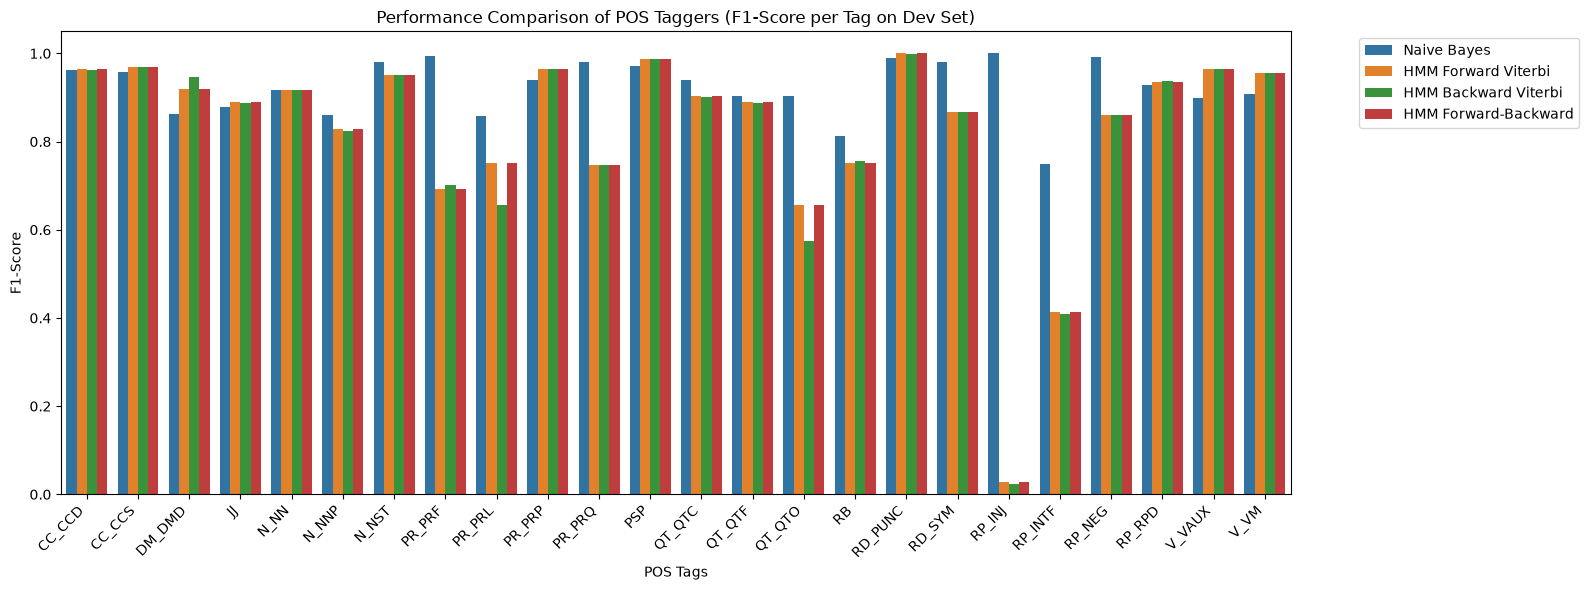

In [5]:
tags = sorted(list(set(y_true_dev)))

f1_nb = f1_score(y_dev, y_dev_pred_nb, labels=tags, average=None, zero_division=0)
f1_fwd = f1_score(y_true_dev, y_pred_dev_fwd, labels=tags, average=None, zero_division=0)
f1_bwd = f1_score(y_true_dev, y_pred_dev_bwd, labels=tags, average=None, zero_division=0)
f1_fb = f1_score(y_true_dev, y_pred_dev_fb, labels=tags, average=None, zero_division=0)

df_results = pd.DataFrame({
    'Tag': tags,
    'Naive Bayes': f1_nb,
    'HMM Forward Viterbi': f1_fwd,
    'HMM Backward Viterbi': f1_bwd,
    'HMM Forward-Backward': f1_fb
})

print(df_results)

# Plotting the F1-score comparison per tag
plt.figure(figsize=(16, 6))
df_melted = df_results.melt(id_vars='Tag', 
                            value_vars=['Naive Bayes', 'HMM Forward Viterbi', 'HMM Backward Viterbi', 'HMM Forward-Backward'],
                            var_name='Model', value_name='F1-Score')

sns.barplot(data=df_melted, x='Tag', y='F1-Score', hue='Model')
plt.xticks(rotation=45, ha='right')
plt.title('Performance Comparison of POS Taggers (F1-Score per Tag on Dev Set)')
plt.xlabel('POS Tags')
plt.ylabel('F1-Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()